# CDCN++ Training on CASIA-FASD (`immada/casia-fasd`)
### High-Performance Face Anti-Spoofing Implementation (CVPR 2020)

Based on the research paper:
> **"Searching Central Difference Convolutional Networks for Face Anti-Spoofing"**  
> *Zitong Yu, Chenxu Zhao, Zezheng Wang, Yunxiao Qin, Zhuo Su, Xiaobai Li, Feng Zhou, Guoying Zhao (CVPR 2020)*

---

### Dataset Structure in `immada/casia-fasd`:
The dataset contains pre-extracted `.png` image frames organized cleanly as:
```text
train/
    live/   --> Label = 1
    spoof/  --> Label = 0
test/
    live/   --> Label = 1
    spoof/  --> Label = 0
```

### Why Previous Run Skipped All Frames:
The previous parser searched for raw video names (`1.avi`, `HR_1`, `train_release`), but your dataset is already processed into clean `live` and `spoof` folders! The loader below directly maps these folders:
- `*/train/live/*` $\to$ **Train Live (1)**
- `*/train/spoof/*` $\to$ **Train Spoof (0)**
- `*/test/live/*` $\to$ **Val Live (1)**
- `*/test/spoof/*` $\to$ **Val Spoof (0)**


In [1]:
# 1. Environment Verification & GPU Setup
import os
import sys
import math
import random
import glob
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR

# Modern PyTorch AMP (Mixed Precision)
try:
    from torch.amp import autocast, GradScaler
    def make_scaler(enabled):
        return GradScaler('cuda', enabled=enabled)
except (ImportError, TypeError):
    from torch.cuda.amp import autocast, GradScaler
    def make_scaler(enabled):
        return GradScaler(enabled=enabled)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Device in use: {device}")
if torch.cuda.is_available():
    print(f"GPU Accelerator: {torch.cuda.get_device_name(0)}")
    torch.backends.cudnn.benchmark = True

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(42)


Device in use: cuda:0
GPU Accelerator: Tesla T4


## 2. Direct Folder Dataset Loader for `immada/casia-fasd`
Directly scans:
- `train/live/` (Live = 1)
- `train/spoof/` (Spoof = 0)
- `test/live/` (Live = 1)
- `test/spoof/` (Spoof = 0)


In [2]:
# 2. Direct Dataset Loader
def load_casia_fasd_dataset(dataset_dir=None, frame_stride=8, max_train=10000, max_val=2500):
    """
    Scans the live and spoof folders directly across train and test splits.
    """
    candidate_roots = [
        dataset_dir,
        "/kaggle/input/datasets/immada/casia-fasd",
        "/kaggle/input/casia-fasd",
        "/kaggle/input/casia-fasd/casia-fasd",
        "./data"
    ]
    
    found_root = None
    for r in candidate_roots:
        if r and os.path.exists(r):
            # Check if train or test exists inside
            subdirs = [d.lower() for d in os.listdir(r)]
            if any(k in subdirs for k in ['train', 'test', 'live', 'spoof']):
                found_root = r
                break

    if not found_root:
        raise FileNotFoundError(f"Could not find CASIA-FASD directory! Checked: {candidate_roots}")

    print(f"Found CASIA-FASD dataset root at: {found_root}")

    train_live, train_spoof = [], []
    val_live, val_spoof = [], []

    # Walk directory and categorize by path components
    for root, dirs, files in os.walk(found_root):
        r_norm = root.replace('\\', '/').lower()
        
        # Check image files
        imgs = [os.path.join(root, f) for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if not imgs:
            continue
        imgs.sort()

        # Strided sampling (e.g. 1 frame every 8 frames to eliminate duplicate video frames)
        sampled_imgs = imgs[::frame_stride] if frame_stride > 1 else imgs

        # Determine Split
        is_test = ('/test' in r_norm) or ('/val' in r_norm)

        # Determine Class
        is_live = ('/live' in r_norm) or ('/real' in r_norm)
        is_spoof = ('/spoof' in r_norm) or ('/fake' in r_norm) or ('/attack' in r_norm)

        if is_live:
            if is_test:
                val_live.extend([(f, 1) for f in sampled_imgs])
            else:
                train_live.extend([(f, 1) for f in sampled_imgs])
        elif is_spoof:
            if is_test:
                val_spoof.extend([(f, 0) for f in sampled_imgs])
            else:
                train_spoof.extend([(f, 0) for f in sampled_imgs])

    print(f"Raw Scanned Candidate Frames (stride={frame_stride}):")
    print(f"  Train: {len(train_live):,} Live, {len(train_spoof):,} Spoof")
    print(f"  Test:  {len(val_live):,} Live, {len(val_spoof):,} Spoof")

    # If test folder had no images, split train 80/20
    if len(val_live) == 0 and len(val_spoof) == 0:
        print("Note: Test split empty, splitting train set 80/20 randomly...")
        random.shuffle(train_live)
        random.shuffle(train_spoof)
        sp_l, sp_s = int(0.8 * len(train_live)), int(0.8 * len(train_spoof))
        val_live = train_live[sp_l:]
        train_live = train_live[:sp_l]
        val_spoof = train_spoof[sp_s:]
        train_spoof = train_spoof[:sp_s]

    # Balance train set
    n_train_each = min(len(train_live), len(train_spoof))
    if max_train:
        n_train_each = min(n_train_each, max_train // 2)

    random.shuffle(train_live)
    random.shuffle(train_spoof)
    train_samples = train_live[:n_train_each] + train_spoof[:n_train_each]
    random.shuffle(train_samples)

    # Balance val set
    n_val_each = min(len(val_live), len(val_spoof))
    if max_val:
        n_val_each = min(n_val_each, max_val // 2)

    random.shuffle(val_live)
    random.shuffle(val_spoof)
    val_samples = val_live[:n_val_each] + val_spoof[:n_val_each]
    random.shuffle(val_samples)

    print(f"\n=== Active Training Dataset Summary ===")
    print(f"Train Set: {len(train_samples):,} images ({n_train_each:,} Live, {n_train_each:,} Spoof)")
    print(f"Val Set:   {len(val_samples):,} images ({n_val_each:,} Live, {n_val_each:,} Spoof)")
    return train_samples, val_samples


## 3. Depth Supervision Targets (Binary Depth Map)
In the CVPR 2020 paper adaptation (`depth_map_default: 1`):
- **Live face:** A $32 \times 32$ map filled with `1.0` (or `0.999` with label smoothing).
- **Spoof face:** A $32 \times 32$ map filled with `0.0`.
- **Classification Threshold:** `0.50` (clean, symmetric boundary).


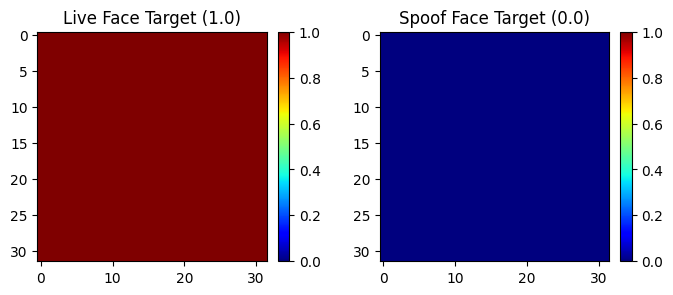

In [3]:
# 3. Depth Supervision Target
GLOBAL_LIVE_DEPTH = np.ones((32, 32), dtype=np.float32)
GLOBAL_SPOOF_DEPTH = np.zeros((32, 32), dtype=np.float32)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
im0 = axes[0].imshow(GLOBAL_LIVE_DEPTH, cmap='jet', vmin=0, vmax=1)
axes[0].set_title("Live Face Target (1.0)")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(GLOBAL_SPOOF_DEPTH, cmap='jet', vmin=0, vmax=1)
axes[1].set_title("Spoof Face Target (0.0)")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## 4. PyTorch Dataset Definition & Transforms


In [4]:
# 4. PyTorch Dataset
class FastFASDataset(Dataset):
    def __init__(self, samples, transform=None, label_smoothing=True):
        self.samples = samples
        self.transform = transform
        scale = 0.999 if label_smoothing else 1.0
        self.live_depth = (GLOBAL_LIVE_DEPTH * scale).astype(np.float32)
        self.spoof_depth = GLOBAL_SPOOF_DEPTH

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]

        try:
            bgr = cv2.imread(img_path)
            if bgr is None:
                img = Image.new('RGB', (256, 256), color=(128, 128, 128))
            else:
                h, w = bgr.shape[:2]
                if h != w:
                    min_dim = min(h, w)
                    start_y = (h - min_dim) // 2
                    start_x = (w - min_dim) // 2
                    bgr = bgr[start_y:start_y + min_dim, start_x:start_x + min_dim]
                rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                img = Image.fromarray(rgb)
        except Exception:
            img = Image.new('RGB', (256, 256), color=(128, 128, 128))

        depth = self.live_depth if label == 1 else self.spoof_depth

        if self.transform:
            img = self.transform(img)

        return img, torch.from_numpy(depth), torch.tensor([float(label)], dtype=torch.float32)


## 5. CDCN++ Architecture & Central Difference Convolution (CDC)

### The CDC Operator
$$y(p_0) = \underbrace{\sum_{p_n \in \mathcal{R}} w(p_n) \cdot x(p_0 + p_n)}_{\text{Vanilla Convolution}} + \theta \cdot \underbrace{\left(-x(p_0) \sum_{p_n \in \mathcal{R}} w(p_n)\right)}_{\text{Central Difference Term}}$$
We use **$\theta = 0.7$** as determined in the CVPR paper.


In [5]:
# 5. CDC & CDCN++ Architecture
class Conv2d_cd(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 padding=1, dilation=1, groups=1, bias=False, theta=0.7):
        super(Conv2d_cd, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size,
                              stride=stride, padding=padding, dilation=dilation,
                              groups=groups, bias=bias)
        self.theta = theta

    def forward(self, x):
        out_normal = self.conv(x)
        if math.fabs(self.theta) < 1e-8:
            return out_normal
        kernel_diff = self.conv.weight.sum(2).sum(2)[:, :, None, None]
        out_diff = F.conv2d(input=x, weight=kernel_diff, bias=self.conv.bias,
                            stride=self.conv.stride, padding=0, groups=self.conv.groups)
        return out_normal - self.theta * out_diff


class SpatialAttention(nn.Module):
    def __init__(self, kernel=3):
        super(SpatialAttention, self).__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size=kernel, padding=kernel // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        feat = torch.cat([avg_out, max_out], dim=1)
        feat = self.conv1(feat)
        return self.sigmoid(feat)


class CDCNpp(nn.Module):
    def __init__(self, basic_conv=Conv2d_cd, theta=0.7):
        super(CDCNpp, self).__init__()
        self.theta = theta
        
        self.stem = nn.Sequential(
            basic_conv(3, 64, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        # Block 1
        self.Block1 = nn.Sequential(
            basic_conv(64, 128, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            basic_conv(128, int(128 * 1.6), kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(int(128 * 1.6)),
            nn.ReLU(inplace=True),
            basic_conv(int(128 * 1.6), 128, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        # Block 2
        self.Block2 = nn.Sequential(
            basic_conv(128, int(128 * 1.2), kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(int(128 * 1.2)),
            nn.ReLU(inplace=True),
            basic_conv(int(128 * 1.2), 128, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            basic_conv(128, int(128 * 1.4), kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(int(128 * 1.4)),
            nn.ReLU(inplace=True),
            basic_conv(int(128 * 1.4), 128, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        # Block 3
        self.Block3 = nn.Sequential(
            basic_conv(128, 128, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            basic_conv(128, int(128 * 1.2), kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(int(128 * 1.2)),
            nn.ReLU(inplace=True),
            basic_conv(int(128 * 1.2), 128, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        self.sa1 = SpatialAttention(kernel=7)
        self.sa2 = SpatialAttention(kernel=5)
        self.sa3 = SpatialAttention(kernel=3)
        self.downsample32x32 = nn.Upsample(size=(32, 32), mode='bilinear', align_corners=False)

        self.head = nn.Sequential(
            basic_conv(128 * 3, 128, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            basic_conv(128, 1, kernel_size=3, stride=1, padding=1, bias=False, theta=theta),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        stem_out = self.stem(x)
        b1_out = self.Block1(stem_out)
        b1_sa = self.sa1(b1_out) * b1_out
        b1_32x32 = self.downsample32x32(b1_sa)

        b2_out = self.Block2(b1_out)
        b2_sa = self.sa2(b2_out) * b2_out
        b2_32x32 = self.downsample32x32(b2_sa)

        b3_out = self.Block3(b2_out)
        b3_sa = self.sa3(b3_out) * b3_out
        b3_32x32 = self.downsample32x32(b3_sa)

        concat_feat = torch.cat([b1_32x32, b2_32x32, b3_32x32], dim=1)
        depth_out = self.head(concat_feat).squeeze(1)
        return depth_out


## 6. Loss Function: MSE Loss + Contrastive Depth Loss ($L_{\text{CDL}}$)


In [6]:
# 6. Loss Functions
def contrast_depth_conv(depth_tensor, device):
    kernel_filters = [
        [[1, 0, 0], [0, -1, 0], [0, 0, 0]],
        [[0, 1, 0], [0, -1, 0], [0, 0, 0]],
        [[0, 0, 1], [0, -1, 0], [0, 0, 0]],
        [[0, 0, 0], [1, -1, 0], [0, 0, 0]],
        [[0, 0, 0], [0, -1, 1], [0, 0, 0]],
        [[0, 0, 0], [0, -1, 0], [1, 0, 0]],
        [[0, 0, 0], [0, -1, 0], [0, 1, 0]],
        [[0, 0, 0], [0, -1, 0], [0, 0, 1]]
    ]
    filters_np = np.array(kernel_filters, dtype=np.float32)
    filters_t = torch.from_numpy(filters_np).unsqueeze(1).to(device)

    inp = depth_tensor.unsqueeze(1).expand(-1, 8, -1, -1)
    contrast = F.conv2d(inp, weight=filters_t, padding=1, groups=8)
    return contrast


class ContrastDepthLoss(nn.Module):
    def __init__(self, device):
        super(ContrastDepthLoss, self).__init__()
        self.device = device
        self.criterion = nn.MSELoss()

    def forward(self, pred_depth, gt_depth):
        contrast_pred = contrast_depth_conv(pred_depth, self.device)
        contrast_gt = contrast_depth_conv(gt_depth, self.device)
        return self.criterion(contrast_pred, contrast_gt)


class DepthLoss(nn.Module):
    def __init__(self, device, contrast_weight=0.5):
        super(DepthLoss, self).__init__()
        self.device = device
        self.contrast_weight = contrast_weight
        self.mse_loss = nn.MSELoss()
        self.contrast_loss = ContrastDepthLoss(device)

    def forward(self, pred_depth, gt_depth):
        l_mse = self.mse_loss(pred_depth, gt_depth)
        l_cdl = self.contrast_loss(pred_depth, gt_depth)
        return l_mse + self.contrast_weight * l_cdl


## 7. Training & Evaluation Engine


In [7]:
# 7. Training & Evaluation Functions
def evaluate_predictions(scores, labels, threshold=0.50):
    preds = (scores >= threshold).astype(np.int32)
    acc = np.mean(preds == labels)
    return acc, preds


def find_optimal_threshold(scores, labels):
    best_acc = 0.0
    best_thresh = 0.50
    for t in np.linspace(0.05, 0.95, 45):
        preds = (scores >= t).astype(np.int32)
        acc = np.mean(preds == labels)
        if acc > best_acc:
            best_acc = acc
            best_thresh = t
    return best_thresh, best_acc


def train_one_epoch(model, dataloader, criterion, optimizer, scaler, device, threshold=0.50):
    model.train()
    running_loss = 0.0
    all_scores = []
    all_labels = []

    for imgs, gt_depths, labels in dataloader:
        imgs = imgs.to(device, non_blocking=True)
        gt_depths = gt_depths.to(device, non_blocking=True)
        labels_arr = labels.squeeze().numpy()

        optimizer.zero_grad(set_to_none=True)

        with autocast('cuda' if device.type == 'cuda' else 'cpu', enabled=(device.type == 'cuda')):
            pred_depths = model(imgs)
            loss = criterion(pred_depths, gt_depths)

        if device.type == 'cuda':
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        scores = torch.mean(pred_depths, dim=(1, 2)).detach().cpu().numpy()
        all_scores.extend(scores.flatten())
        all_labels.extend(labels_arr.flatten())

    all_scores = np.array(all_scores)
    all_labels = np.array(all_labels)
    epoch_loss = running_loss / max(len(all_labels), 1)
    epoch_acc, _ = evaluate_predictions(all_scores, all_labels, threshold=threshold)
    return epoch_loss, epoch_acc


def validate_model(model, dataloader, criterion, device, threshold=0.50):
    model.eval()
    running_loss = 0.0
    all_scores = []
    all_labels = []

    with torch.no_grad():
        for imgs, gt_depths, labels in dataloader:
            imgs = imgs.to(device, non_blocking=True)
            gt_depths = gt_depths.to(device, non_blocking=True)
            labels_arr = labels.squeeze().numpy()

            with autocast('cuda' if device.type == 'cuda' else 'cpu', enabled=(device.type == 'cuda')):
                pred_depths = model(imgs)
                loss = criterion(pred_depths, gt_depths)

            running_loss += loss.item() * imgs.size(0)
            scores = torch.mean(pred_depths, dim=(1, 2)).detach().cpu().numpy()
            all_scores.extend(scores.flatten())
            all_labels.extend(labels_arr.flatten())

    all_scores = np.array(all_scores)
    all_labels = np.array(all_labels)

    val_loss = running_loss / max(len(all_labels), 1)
    fixed_acc, _ = evaluate_predictions(all_scores, all_labels, threshold=threshold)
    best_thresh, best_acc = find_optimal_threshold(all_scores, all_labels)

    live_mask = (all_labels == 1)
    spoof_mask = (all_labels == 0)
    live_mean_score = float(np.mean(all_scores[live_mask])) if np.any(live_mask) else 0.0
    spoof_mean_score = float(np.mean(all_scores[spoof_mask])) if np.any(spoof_mask) else 0.0

    return val_loss, fixed_acc, best_acc, best_thresh, live_mean_score, spoof_mean_score


## 8. Hyperparameter Configuration & DataLoader Setup


In [8]:
# 8. Hyperparameters
CONFIG = {
    'dataset_dir': '/kaggle/input/datasets/immada/casia-fasd/casia-fasd', # Path to immada/casia-fasd
    'input_size': (256, 256),
    'batch_size': 32,            # Fast batching
    'num_workers': 4,            # Kaggle 4 CPU cores
    'frame_stride': 8,           # Samples 1 frame every 8 frames
    'max_train_samples': 10000,  # 10k samples
    'max_val_samples': 2500,     # 2.5k val samples
    'learning_rate': 0.0005,     # Scaled for batch size 32
    'weight_decay': 0.00005,
    'epochs': 15,                # 20 epochs gives full convergence
    'theta': 0.7,                # CDC optimal theta
    'eval_threshold': 0.50,      # Symmetric boundary for binary depth
    'checkpoint_path': 'best_cdcnpp.pth'
}

train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Resize(CONFIG['input_size']),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

val_transform = transforms.Compose([
    transforms.Resize(CONFIG['input_size']),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Load and balance dataset
train_samples, val_samples = load_casia_fasd_dataset(
    dataset_dir=CONFIG['dataset_dir'],
    frame_stride=CONFIG['frame_stride'],
    max_train=CONFIG['max_train_samples'],
    max_val=CONFIG['max_val_samples']
)

train_dataset = FastFASDataset(train_samples, transform=train_transform)
val_dataset = FastFASDataset(val_samples, transform=val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=True,
    num_workers=CONFIG['num_workers'],
    pin_memory=True,
    persistent_workers=(CONFIG['num_workers'] > 0),
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    num_workers=CONFIG['num_workers'],
    pin_memory=True,
    persistent_workers=(CONFIG['num_workers'] > 0)
)

print(f"Iterations per Epoch: {len(train_loader)} (Train), {len(val_loader)} (Val)")

model = CDCNpp(theta=CONFIG['theta']).to(device)
criterion = DepthLoss(device=device, contrast_weight=0.5)
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])
scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'], eta_min=1e-6)
scaler = make_scaler(enabled=(device.type == 'cuda'))

print(f"CDCN++ Model Ready ({sum(p.numel() for p in model.parameters() if p.requires_grad):,} parameters).")


Found CASIA-FASD dataset root at: /kaggle/input/datasets/immada/casia-fasd/casia-fasd
Raw Scanned Candidate Frames (stride=8):
  Train: 2,377 Live, 4,842 Spoof
  Test:  1,266 Live, 6,958 Spoof

=== Active Training Dataset Summary ===
Train Set: 4,754 images (2,377 Live, 2,377 Spoof)
Val Set:   2,500 images (1,250 Live, 1,250 Spoof)
Iterations per Epoch: 149 (Train), 79 (Val)
CDCN++ Model Ready (2,257,352 parameters).


In [9]:
# Run Accelerated Training Loop
import time

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'best_val_acc': []}
best_overall_acc = 0.0

print(f"Starting training for {CONFIG['epochs']} epochs on CASIA-FASD...\n")
total_start = time.time()

for epoch in range(1, CONFIG['epochs'] + 1):
    ep_start = time.time()
    t_loss, t_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler, device,
        threshold=CONFIG['eval_threshold']
    )
    v_loss, v_acc, best_acc, best_th, live_sc, spoof_sc = validate_model(
        model, val_loader, criterion, device,
        threshold=CONFIG['eval_threshold']
    )
    scheduler.step()
    ep_time = time.time() - ep_start

    history['train_loss'].append(t_loss)
    history['train_acc'].append(t_acc)
    history['val_loss'].append(v_loss)
    history['val_acc'].append(v_acc)
    history['best_val_acc'].append(best_acc)

    print(f"Epoch [{epoch:02d}/{CONFIG['epochs']}] ({ep_time:.1f}s) | "
          f"Train Loss: {t_loss:.4f} Acc: {t_acc*100:.1f}% | "
          f"Val Loss: {v_loss:.4f} Acc: {v_acc*100:.1f}% | "
          f"Best Acc: {best_acc*100:.1f}% (Thresh: {best_th:.2f}) | "
          f"[Live: {live_sc:.3f}, Spoof: {spoof_sc:.3f}]")

    target_acc = max(v_acc, best_acc)
    if target_acc >= best_overall_acc:
        best_overall_acc = target_acc
        torch.save({
            'epoch': epoch,
            'state_dict': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'best_acc': best_overall_acc,
            'best_threshold': best_th,
            'theta': CONFIG['theta']
        }, CONFIG['checkpoint_path'])
        print(f"  --> Saved new best checkpoint (Acc: {best_overall_acc*100:.1f}%) to {CONFIG['checkpoint_path']}")

total_elapsed = time.time() - total_start
print(f"\nAll {CONFIG['epochs']} Epochs Completed in {total_elapsed/60:.2f} minutes!")


Starting training for 15 epochs on CASIA-FASD...

Epoch [01/15] (270.6s) | Train Loss: 0.3150 Acc: 53.7% | Val Loss: 0.2436 Acc: 63.8% | Best Acc: 76.0% (Thresh: 0.36) | [Live: 0.478, Spoof: 0.336]
  --> Saved new best checkpoint (Acc: 76.0%) to best_cdcnpp.pth
Epoch [02/15] (221.3s) | Train Loss: 0.1875 Acc: 84.0% | Val Loss: 0.1833 Acc: 86.8% | Best Acc: 87.2% (Thresh: 0.46) | [Live: 0.625, Spoof: 0.229]
  --> Saved new best checkpoint (Acc: 87.2%) to best_cdcnpp.pth
Epoch [03/15] (221.3s) | Train Loss: 0.1070 Acc: 95.3% | Val Loss: 0.1298 Acc: 92.8% | Best Acc: 92.8% (Thresh: 0.50) | [Live: 0.722, Spoof: 0.148]
  --> Saved new best checkpoint (Acc: 92.8%) to best_cdcnpp.pth
Epoch [04/15] (221.0s) | Train Loss: 0.0865 Acc: 97.1% | Val Loss: 0.1092 Acc: 93.5% | Best Acc: 94.0% (Thresh: 0.62) | [Live: 0.848, Spoof: 0.191]
  --> Saved new best checkpoint (Acc: 94.0%) to best_cdcnpp.pth
Epoch [05/15] (221.0s) | Train Loss: 0.0621 Acc: 98.6% | Val Loss: 0.0973 Acc: 95.3% | Best Acc: 95.4%

## 9. Training Curves and Loss Analysis


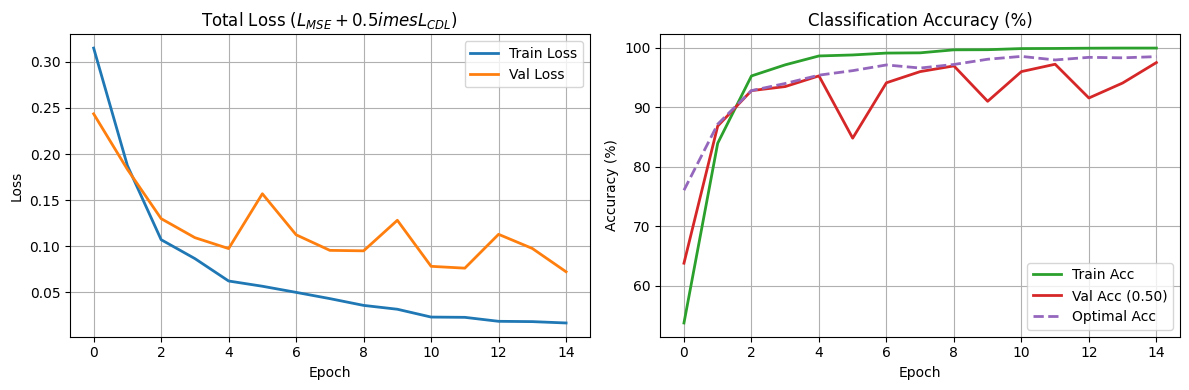

In [10]:
# Plot Training Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history['train_loss'], label='Train Loss', color='tab:blue', lw=2)
ax1.plot(history['val_loss'], label='Val Loss', color='tab:orange', lw=2)
ax1.set_title("Total Loss ($L_{MSE} + 0.5 \times L_{CDL}$)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(np.array(history['train_acc']) * 100, label='Train Acc', color='tab:green', lw=2)
ax2.plot(np.array(history['val_acc']) * 100, label='Val Acc (0.50)', color='tab:red', lw=2)
ax2.plot(np.array(history['best_val_acc']) * 100, label='Optimal Acc', color='tab:purple', lw=2, linestyle='--')
ax2.set_title("Classification Accuracy (%)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()


## 10. Qualitative Validation on Test Faces


Loaded best checkpoint: Val Acc = 98.6%, Threshold = 0.32


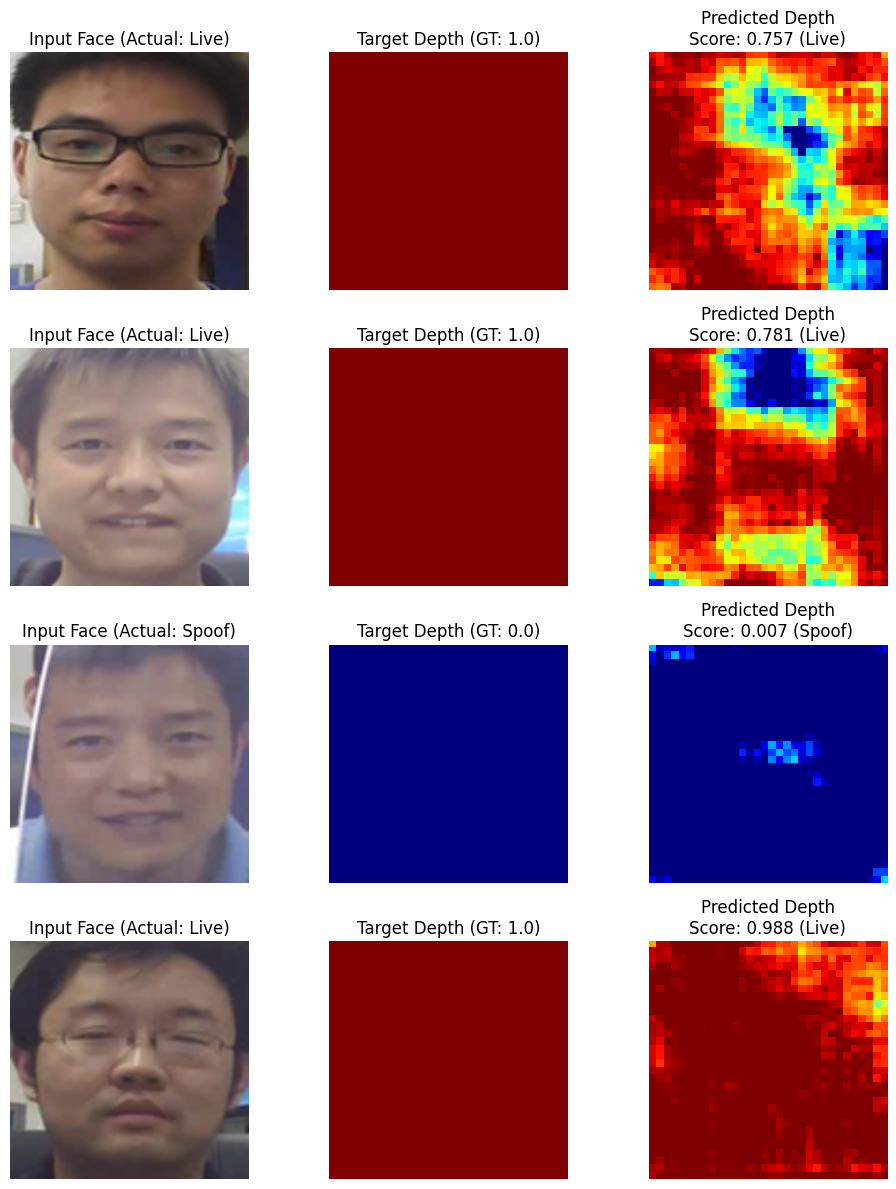

In [11]:
# Qualitative Inspection & Test Inference
if os.path.exists(CONFIG['checkpoint_path']):
    ckpt = torch.load(CONFIG['checkpoint_path'], map_location=device,weights_only= False)
    model.load_state_dict(ckpt['state_dict'])
    eval_threshold = ckpt.get('best_threshold', CONFIG['eval_threshold'])
    print(f"Loaded best checkpoint: Val Acc = {ckpt['best_acc']*100:.1f}%, Threshold = {eval_threshold:.2f}")
else:
    eval_threshold = CONFIG['eval_threshold']

model.eval()
test_batch_size = min(4, len(val_dataset))
sample_indices = random.sample(range(len(val_dataset)), test_batch_size)

fig, axes = plt.subplots(test_batch_size, 3, figsize=(10, 3 * test_batch_size))
if test_batch_size == 1:
    axes = np.expand_dims(axes, 0)

with torch.no_grad():
    for row, idx in enumerate(sample_indices):
        img_tensor, gt_depth, label_t = val_dataset[idx]
        with autocast('cuda' if device.type == 'cuda' else 'cpu', enabled=(device.type == 'cuda')):
            pred_depth = model(img_tensor.unsqueeze(0).to(device)).squeeze().cpu().numpy()
        gt_depth = gt_depth.numpy()

        img_disp = img_tensor.permute(1, 2, 0).numpy()
        img_disp = np.clip((img_disp * 0.5 + 0.5), 0, 1)

        score = float(np.mean(pred_depth))
        decision = "Live" if score >= eval_threshold else "Spoof"
        actual = "Live" if int(label_t.item()) == 1 else "Spoof"

        axes[row, 0].imshow(img_disp)
        axes[row, 0].set_title(f"Input Face (Actual: {actual})")
        axes[row, 0].axis('off')

        axes[row, 1].imshow(gt_depth, cmap='jet', vmin=0, vmax=1)
        axes[row, 1].set_title(f"Target Depth (GT: {np.mean(gt_depth):.1f})")
        axes[row, 1].axis('off')

        axes[row, 2].imshow(pred_depth, cmap='jet', vmin=0, vmax=1)
        axes[row, 2].set_title(f"Predicted Depth\nScore: {score:.3f} ({decision})")
        axes[row, 2].axis('off')

plt.tight_layout()
plt.show()
